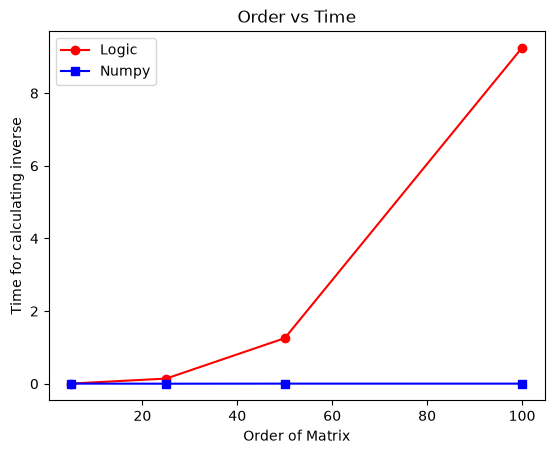

In [12]:
import math
import numpy as np
import matplotlib.pyplot as plt
import time

def LUD_step(matrixA):
    rows,cols = matrixA.shape
    U = matrixA.copy()
    L = np.eye(rows)
    for i in range(1,rows,1):
        for j in range(0,i,1):
            prefac = (U[i][j] / U[j][j])
            L[i,j] = prefac
            U[i]=U[i] - (prefac*U[j])
    return L,U

def augmented_matrix(matrixA,vectorB):
    rows,cols = matrixA.shape
    vectorB_new = vectorB.reshape(-1,1)   #To change the vector from row matrix to column matrix
    aug = np.concatenate((matrixA,vectorB_new), axis = 1)
    #print(aug)
    return aug

def forward_substitution_LU(L,vectorB):
    aug = augmented_matrix(L,vectorB)
    rows,cols = aug.shape
    y = np.zeros(rows)
    for i in range(0,rows,1):
        sum = 0
        for j in range(0,rows,1):
            sum = sum + (y[j] * aug[i][j])
        y[i] = (aug[i][rows] - sum)/(aug[i][i])
    #print(y)
    return y

def backward_substitution_LU(U,y):
    aug = augmented_matrix(U,y)
    rows,cols = aug.shape
    x = np.zeros(rows)
    for i in range(rows-1,-1,-1):
        sum = 0
        for j in range(0,rows,1):
            sum = sum + (x[j] * aug[i][j])
        x[i] = (aug[i][rows] - sum)/(aug[i][i])
    #print(x)
    return x

def LUD(matrixA,vectorB):
    L,U = LUD_step(matrixA)
    y = forward_substitution_LU(L,vectorB)
    x = backward_substitution_LU(U,y)
    return x

def creating_matrix(n):
    matrixA = np.random.rand(n,n) 
    I = np.eye(n,n)
    return matrixA, I

def creating_inverse(n,matrixA,I):
    L,U = LUD_step(matrixA)
    inv = []
    for i in range(0,n,1):
        vectorB=[]
        for j in range(0,n,1):
            element = I[i][j]
            vectorB.append(element)
        vectorB_transpose = np.transpose(vectorB)
        inv.append(LUD(matrixA,vectorB_transpose))
    return np.transpose(inv)

def creating_direct_inverse(matrixA):
    A_inv = np.linalg.inv(matrixA)
    return A_inv
    
N = [5,25,50,100]
time1 = []
time2 = []
for n in N:
    matrixA,I = creating_matrix(n)
    start1 = time.perf_counter()
    inverse_logic = creating_inverse(n,matrixA,I)
    end1 = time.perf_counter()
    time1.append(end1 - start1)
    start2 = time.perf_counter()
    inverse_numpy = creating_direct_inverse(matrixA)
    end2 = time.perf_counter()
    time2.append(end2 - start2)
    #print(n, np.allclose(inverse_logic, inverse_numpy))
plt.plot(N,time1, color = 'red', marker = 'o', label = 'Logic')
plt.plot(N,time2, color = 'blue', marker = 's', label = 'Numpy')
plt.xlabel('Order of Matrix')
plt.ylabel('Time for calculating inverse')
plt.title('Order vs Time')
plt.legend()
plt.show()

